# Capítulo 3 · Actividad: análisis de datos con NumPy, pandas y matplotlib

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_03/01_actividad_numpy_pandas.ipynb)

En esta actividad haces de **analista de datos**: vas a responder preguntas sobre datos reales con **NumPy** y **pandas**, y después los visualizarás con **matplotlib** y **seaborn**. Lo importante no es solo que el código funcione, sino que **sepas interpretar los resultados**.

### Antes de empezar

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia. Si editas el original tendrás conflictos al sincronizar tu fork.
2. Si todavía no tienes los datos, descárgalos desde la raíz del repo:
   ```bash
   uv run python scripts/download_data.py
   ```
3. Ten a mano las notebooks de clase de `notebooks/lectures/chapter_03/`: `01_numpy`, `02_pandas` y `03_matplotlib`.

### Cómo trabajar

- Cada ejercicio tiene una celda `# Tu código aquí`. Puedes añadir todas las celdas que necesites.
- En las celdas ✍️ responde con tus palabras y **apoya tus respuestas con números** de tus resultados.
- En las partes 1 y 2, las 💡 **pistas** te recuerdan funciones. Si una función no salió en clase, la pista explica cómo usarla. La parte 3 no tiene pistas.
- Al terminar, ejecuta **Kernel → Restart & Run All** y comprueba que todo funciona de arriba abajo.

| Parte | Datos | Herramienta |
|---|---|---|
| 1. La cafetería | ventas de un mes (generadas en la notebook) | NumPy |
| 2. Las propinas | `data/tips.csv` | pandas (+ un poco de NumPy) |
| 3. Visualización | cafetería, propinas y `data/penguins.csv` | matplotlib y seaborn |

In [45]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"
print("Carpeta de datos:", DATA_DIR)

Carpeta de datos: c:\Users\flavs\Documents\ml-course\data


---
## Parte 1 · La cafetería ☕ (NumPy)

Una cafetería vende 5 productos y ha registrado cuántas unidades vendió de cada uno durante **4 semanas** (28 días, de lunes a domingo). La dueña quiere saber cuánto gana, qué días van mejor y qué producto le conviene más.

Ejecuta la siguiente celda para generar los datos. **No hace falta que la modifiques ni que entiendas cada línea.**

In [46]:
# Datos de la cafetería (no hace falta modificar esta celda)
rng = np.random.default_rng(42)

productos = np.array(["café", "latte", "té", "croissant", "sándwich"])
precios = np.array([1.5, 2.8, 1.2, 2.0, 4.5])       # precio de cada producto, en $

# Unidades vendidas cada día: los fines de semana se vende un 50% más
dia_semana = np.tile(np.arange(7), 4)                # 0 = lunes, ..., 6 = domingo
factor = np.where(dia_semana >= 5, 1.5, 1.0)
promedio = np.outer(factor, [30, 22, 12, 18, 9])     # ventas esperadas por día y producto
ventas_planas = rng.poisson(promedio).ravel()         # ¡todo en una sola fila!

print(ventas_planas[:10], "...")
print("Número de valores:", ventas_planas.size)

[35 28  7 16 13 29 16 10 18 11] ...
Número de valores: 140


### Ejercicio 1 · Dar forma a los datos

`ventas_planas` tiene 140 números seguidos: primero las ventas de los 5 productos del día 1, después las del día 2, y así sucesivamente.

a) Crea una matriz `ventas` con forma `(28, 5)`: una **fila por día** y una **columna por producto** (en el mismo orden que `productos`).

b) Imprime su `shape`, `ndim`, `size` y `dtype`.

c) ¿Cuántos cafés se vendieron el primer día? Comprueba que coincide con `ventas_planas[0]`.

> 💡 **Pista:** `reshape`.

In [47]:
# Tu código aquí
#Inciso a
ventas = ventas_planas.reshape(28,5)
print(ventas)
#Inciso b
print(ventas.shape)
print(ventas.ndim)
print(ventas.size)
print(ventas.dtype)
#Inciso c
print(f"Los café vendidos en el primer dia: {ventas[0,0]} unidades")

[[35 28  7 16 13]
 [29 16 10 18 11]
 [33 17 15 17 10]
 [29 21  9 15  8]
 [34 17  8 17  8]
 [49 29 25 22 14]
 [53 37 20 29 12]
 [30 16 13 26  7]
 [30 23  9 18  6]
 [26 25  9 19  9]
 [38 22 15 16  8]
 [37 19  8 14 10]
 [57 29 20 20 20]
 [44 39 14 29 15]
 [28 24 11 14  7]
 [39 19  7  9  8]
 [24 18 11 16 10]
 [35 22 16 16  7]
 [28 30 10 23 10]
 [50 44 28 28 11]
 [34 27 19 27 17]
 [22 14 11 20  9]
 [34 31 12 27  7]
 [26 21 17 23  7]
 [35 30  3  9 10]
 [23 26 16 21  8]
 [38 32 20 21 11]
 [49 45 18 27  9]]
(28, 5)
2
140
int64
Los café vendidos en el primer dia: 35 unidades


### Ejercicio 2 · Indexación

Obtén, usando índices y *slicing* sobre `ventas`:

a) Las ventas de todos los productos el **primer día**.

b) Las ventas de **latte** (columna 1) durante todo el mes.

c) Las ventas de la **última semana** (los últimos 7 días). Comprueba que su forma es `(7, 5)`.

d) Las ventas de **croissant y sándwich** (las dos últimas columnas) durante la **primera semana**.

> 💡 **Pista:** `M[filas, columnas]`. Recuerda que los índices negativos cuentan desde el final.

In [48]:
# Tu código aquí
#Inciso a
print(ventas[0])
print("\n")
#Inciso b
print(ventas[:,1])
print("\n")
#Inciso c
print(ventas[-8:-1,:])
print(ventas[-8:-1,:].shape)
print("\n")
#Inciso d
print(ventas[0:6,3:5])

[35 28  7 16 13]


[28 16 17 21 17 29 37 16 23 25 22 19 29 39 24 19 18 22 30 44 27 14 31 21
 30 26 32 45]


[[34 27 19 27 17]
 [22 14 11 20  9]
 [34 31 12 27  7]
 [26 21 17 23  7]
 [35 30  3  9 10]
 [23 26 16 21  8]
 [38 32 20 21 11]]
(7, 5)


[[16 13]
 [18 11]
 [17 10]
 [15  8]
 [17  8]
 [22 14]]


### Ejercicio 3 · Ingresos

a) Calcula la matriz `ingresos` (forma `(28, 5)`): lo que se ingresó por cada producto cada día.

b) ¿Cuánto ingresó la cafetería en todo el mes?

c) Crea `ingreso_diario`, un array con el ingreso total de **cada día** (forma `(28,)`).

d) ¿Cuál fue el ingreso diario medio, el máximo y el mínimo?

> 💡 **Pistas:**
> - `ventas * precios` multiplica **cada fila** de `ventas` por el vector `precios`, elemento a elemento: la columna del café por 1.5, la del latte por 2.8… (este mecanismo se llama *broadcasting*).
> - `M.sum()` suma todo. `M.sum(axis=1)` suma **cada fila** y devuelve un resultado por fila; `M.sum(axis=0)` suma **cada columna**.

In [49]:
# Tu código aquí
#Inciso a
ingresos = ventas * precios
#print(ingresos)
#print("\n")
#Inciso b
total = ingresos.sum()
print(f"La cafetería ha ingresado un total de ${total} durante todo el mes.\n")
#Inciso c
ingresos_diarios = ingresos.sum(axis=1)
print(ingresos_diarios.reshape(28,1))
print("\n")
#Inciso d
ingreso_d_medio = ingresos_diarios.mean()
ingreso_d_max = ingresos_diarios.max()
ingresos_d_min = ingresos_diarios.min()
print(f"El ingreso diario promedio es de ${ingreso_d_medio}")
print(f"El ingreso diario máximo es de ${ingreso_d_max}")
print(f"El ingreso diario mínimo es de ${ingresos_d_min}")

La cafetería ha ingresado un total de $6342.5 durante todo el mes.

[[229.8]
 [185.8]
 [194.1]
 [179.1]
 [178.2]
 [291.7]
 [319.1]
 [188.9]
 [183.2]
 [198.3]
 [204.6]
 [191.3]
 [320.7]
 [317.5]
 [181.9]
 [174.1]
 [176.6]
 [196.8]
 [229. ]
 [337.3]
 [279.9]
 [165.9]
 [237.7]
 [195.7]
 [203.1]
 [204.5]
 [262.1]
 [315.6]]


El ingreso diario promedio es de $226.5178571428572
El ingreso diario máximo es de $337.29999999999995
El ingreso diario mínimo es de $165.89999999999998


### Ejercicio 4 · Días buenos y días flojos

Usa este array con el número de cada día (del 1 al 28):
```python
dias = np.arange(1, 29)
```

a) Crea una máscara con los días cuyo ingreso supera el **ingreso diario medio** y muestra **qué días** fueron.

b) ¿**Cuántos** días fueron?

c) Crea un array que diga `"bueno"` o `"flojo"` para cada día, según si supera o no la media.

d) Calcula `dias[mascara] % 7` (el resto de dividir entre 7). El día 1 fue lunes, así que un resto de **6** es sábado y un resto de **0** es domingo. ¿Qué tienen en común los días buenos?

> 💡 **Pistas:** `.sum()` sobre una máscara cuenta los `True`, porque `True` vale 1 y `False` vale 0. Para c), `np.where`.

In [50]:
# Tu código aquí
dias = np.arange(1,29)

#Inciso a
mascara = ingresos_diarios >= ingreso_d_medio
dias_m = dias[mascara]
print(dias_m)
#Inciso b
print(dias_m.size)
#Inciso c
desempeño = np.where(ingresos_diarios >= ingreso_d_medio, "bueno", "flojo")
print(desempeño)
#Inciso d
print(dias_m%7)

[ 1  6  7 13 14 19 20 21 23 27 28]
11
['bueno' 'flojo' 'flojo' 'flojo' 'flojo' 'bueno' 'bueno' 'flojo' 'flojo'
 'flojo' 'flojo' 'flojo' 'bueno' 'bueno' 'flojo' 'flojo' 'flojo' 'flojo'
 'bueno' 'bueno' 'bueno' 'flojo' 'bueno' 'flojo' 'flojo' 'flojo' 'bueno'
 'bueno']
[1 6 0 6 0 5 6 0 2 6 0]


✍️ **Tu respuesta:** 

### Ejercicio 5 · Análisis por semanas

a) Reorganiza `ingreso_diario` en una matriz `por_semana` de forma `(4, 7)`: una fila por semana y una columna por día (lunes a domingo).

b) ¿Cuánto se ingresó **cada semana**?

c) ¿Cuál es el ingreso medio de **cada día de la semana**? ¿Qué día se vende más? Usa:
```python
nombres_dias = np.array(["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"])
```

d) Compara el ingreso medio de un día de **fin de semana** con el de un día **entre semana**. ¿Cuántas veces más se ingresa en fin de semana?

> 💡 **Pistas:** `axis=1` da un resultado por fila (por semana) y `axis=0` uno por columna (por día de la semana). `arr.argmax()` devuelve la **posición** del valor máximo; úsala como índice en `nombres_dias`.

In [51]:
# Tu código aquí
#Inciso a
por_semana =  ingresos_diarios.reshape(4,7)
print(por_semana)
print("\n")
#Inciso b
print(por_semana.sum(axis=1))
print("\n")
#Inciso c
nombres_dias = np.array(["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"])
mascara_prom_max = por_semana.mean(axis=0).argmax()
print(nombres_dias[mascara_prom_max])
print("\n")
#Inciso d
#Se compara el dia lunes con el dia domingo
Lunes = por_semana[:,0].mean()
Domingo = por_semana[:,-1].mean()
print(f"hay una diferencia de ${Domingo -Lunes} entre el ingreso promedio del dia lunes con respecto al dia domingo")


[[229.8 185.8 194.1 179.1 178.2 291.7 319.1]
 [188.9 183.2 198.3 204.6 191.3 320.7 317.5]
 [181.9 174.1 176.6 196.8 229.  337.3 279.9]
 [165.9 237.7 195.7 203.1 204.5 262.1 315.6]]


[1577.8 1604.5 1575.6 1584.6]


Domingo


hay una diferencia de $116.4 entre el ingreso promedio del dia lunes con respecto al dia domingo


### Ejercicio 6 · El producto estrella

a) Calcula el ingreso total de **cada producto** en el mes.

b) ¿Qué **porcentaje** del ingreso total aporta cada producto? Redondea a 1 decimal.

c) ¿Qué producto genera **más dinero**? ¿Y cuál vende **más unidades**?

> 💡 **Pista:** `axis=0` y `argmax`, igual que en el ejercicio anterior.

In [52]:
# Tu código aquí
#Inciso a
c_producto = ingresos.sum(axis=0)
print(c_producto)
print("\n")
#Inciso b
porcentaje = (c_producto/total)*100
print(porcentaje.astype(int))
print("\n")
#Inciso c
mascara_n_max_ventas = ventas.sum(axis=0).argmax()
mascara_c_pdcto_max = c_producto.argmax()
print(f"El producto mas vendido es: {productos[mascara_n_max_ventas]}")
print(f"El producto que genera mas dinero es: {productos[mascara_c_pdcto_max]}")

[1483.5 2018.8  457.2 1114.  1269. ]


[23 31  7 17 20]


El producto mas vendido es: café
El producto que genera mas dinero es: latte


✍️ **Pregunta:** ¿por qué el producto que más se vende no es el que más dinero deja? Si fueras la dueña, ¿qué harías con esta información?

✍️ **Tu respuesta:** 
Debido a que el café es mas barato y rapido de hacer que el latte, tiende a venderse mucho más. Aqui seria necesario subir el precio del café porque hay una mayor demanda, por lo tanto, generaría un mayor rendimiento en el negocio.

---
## Parte 2 · Las propinas 💵 (pandas)

Un camarero anotó, durante varias semanas, cada mesa que atendió: cuánto pagaron, cuánta propina dejaron y algunos datos de la mesa. Queremos responder una pregunta: **¿de qué depende la propina?**

El archivo es `data/tips.csv` y tiene estas columnas:

| Columna | Significado |
|---|---|
| `total_bill` | importe de la cuenta, en $ |
| `tip` | propina, en $ |
| `sex` | sexo de quien pagó (`Female` / `Male`) |
| `smoker` | si en la mesa había fumadores (`Yes` / `No`) |
| `day` | día de la semana (`Thur`, `Fri`, `Sat`, `Sun`) |
| `time` | `Lunch` (comida) o `Dinner` (cena) |
| `size` | número de personas en la mesa |

### Ejercicio 7 · Primer vistazo

a) Carga el archivo en un DataFrame llamado `propinas`.

b) Explóralo con `shape`, `head`, `info` y `describe`.

c) ¿Cuántas mesas hay de cada día? ¿Y de cada momento (comida/cena)?

In [53]:
# Tu código aquí
# Importamos la libreria
from pathlib import Path

import pandas as pd

#Subimos el archivo de la carpeta data
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

#Cargamsos el CSV
propinas = pd.read_csv(DATA_DIR/"tips.csv")
print(propinas.shape)
print("\n")
print(propinas.head())
print("\n")
print(propinas.info())
print("\n")
print(propinas.describe())

(244, 7)


   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    str    
 3   smoker      244 non-null    str    
 4   day         244 non-null    str    
 5   time        244 non-null    str    
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 13.5 KB
None


       total_bill         tip        size
count  244.000000  244.000000  244.000000
mean    19.785943    2.998279    2.569672
std      

In [54]:
dias=propinas["day"].value_counts()
horario = propinas["time"].value_counts()
print(dias)
print("\n")
print(horario)
print("\n")
print(propinas["total_bill"].max())
print(propinas["size"].max())

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64


time
Dinner    176
Lunch      68
Name: count, dtype: int64


50.81
6


✍️ **Pregunta:** ¿cuántas mesas hay? ¿Falta algún dato? ¿Cuál fue la cuenta más alta y cuál la mesa más grande?

✍️ **Tu respuesta:** Hay 244 mesas, la cuenta mas alta de fue $50.81 y la mesa mas grande fue de 6 personas. 


### Ejercicio 8 · Traducir los datos

Para trabajar más cómodos, vamos a pasar todo a español.

a) Renombra las columnas: `total_bill` → `cuenta`, `tip` → `propina`, `sex` → `sexo`, `smoker` → `fumador`, `day` → `dia`, `time` → `momento`, `size` → `personas`.

b) Traduce los valores:
- `dia`: `Thur` → `Jueves`, `Fri` → `Viernes`, `Sat` → `Sábado`, `Sun` → `Domingo`
- `momento`: `Lunch` → `Comida`, `Dinner` → `Cena`
- `sexo`: `Female` → `Mujer`, `Male` → `Hombre`
- `fumador`: `Yes` → `sí`, `No` → `no`

Comprueba el resultado con `head()`.

> 💡 **Pista:** `rename(columns={...})` y `.map({...})`.

In [55]:
# Tu código aquí
propinas_esp = propinas.copy()
propinas_esp = propinas_esp.rename(columns={"total_bill" : "cuenta", "tip" : "propinas", "sex": "sexo", "smoker": "fumador", "day": "dia", "time": "momento", "size": "personas"})
propinas_esp["sexo"] = propinas_esp["sexo"].map({"Male": "Masculino", "Female": "Femenino"})
propinas_esp["fumador"]=propinas_esp["fumador"].map({"Yes": "Si", "No": "No"})
propinas_esp["dia"]=propinas_esp["dia"].map({"Thur": "Jueves", "Fri": "Viernes", "Sat": "Sábado", "Sun": "Domingo"})
propinas_esp["momento"]=propinas_esp["momento"].map({"Lunch": "Comida", "Dinner": "Cena"})
print(propinas_esp.head())

   cuenta  propinas       sexo fumador      dia momento  personas
0   16.99      1.01   Femenino      No  Domingo    Cena         2
1   10.34      1.66  Masculino      No  Domingo    Cena         3
2   21.01      3.50  Masculino      No  Domingo    Cena         3
3   23.68      3.31  Masculino      No  Domingo    Cena         2
4   24.59      3.61   Femenino      No  Domingo    Cena         4


### Ejercicio 9 · Nuevas columnas

Una propina de 5 $ no significa lo mismo en una cuenta de 15 $ que en una de 50 $. Por eso vamos a crear variables más útiles:

a) `pct_propina`: la propina como **porcentaje** de la cuenta.

b) `cuenta_por_persona`: lo que pagó cada persona de la mesa.

c) `tamaño_mesa`: agrupa `personas` en `"1-2"`, `"3-4"` y `"5-6"`.

d) `generosa`: `"sí"` si la propina es del 20% o más, `"no"` en caso contrario.

> 💡 **Pistas:** operaciones entre columnas, `pd.cut` (con `bins=[0, 2, 4, 6]`) y `np.where`.

In [56]:
# Tu código aquí
#Inciso a
propinas_esp["pct_propina"] = propinas_esp["propinas"]/propinas_esp["cuenta"]*100
#Inciso b
propinas_esp["cuenta_por_persona"]= propinas_esp["cuenta"]/propinas_esp["personas"]
#Inciso c
propinas_esp["tamaño_mesa"] = pd.cut(propinas_esp["personas"], bins = [1,2,4,6], labels = ["1-2","3-4","5-6"])
#Inciso d
propinas_esp["generosa"] = np.where(propinas_esp["pct_propina"] > 20, "si", "no")

print(propinas_esp.head())

   cuenta  propinas       sexo fumador      dia momento  personas  \
0   16.99      1.01   Femenino      No  Domingo    Cena         2   
1   10.34      1.66  Masculino      No  Domingo    Cena         3   
2   21.01      3.50  Masculino      No  Domingo    Cena         3   
3   23.68      3.31  Masculino      No  Domingo    Cena         2   
4   24.59      3.61   Femenino      No  Domingo    Cena         4   

   pct_propina  cuenta_por_persona tamaño_mesa generosa  
0     5.944673            8.495000         1-2       no  
1    16.054159            3.446667         3-4       no  
2    16.658734            7.003333         3-4       no  
3    13.978041           11.840000         1-2       no  
4    14.680765            6.147500         3-4       no  


### Ejercicio 10 · Filtrar y ordenar

a) ¿Cuántas mesas dejaron una propina **generosa** (20% o más)? ¿Qué **proporción** del total representan?

b) ¿Cuántas **cenas de fin de semana** (sábado o domingo) fueron de **4 personas o más**? ¿Cuál fue su porcentaje de propina medio?

c) Muestra las **5 mesas** con mayor `pct_propina`, con las columnas `cuenta`, `propina`, `pct_propina`, `personas` y `dia`.

d) Usa `query` para obtener las mesas con **fumadores** y una cuenta **entre 10 y 20 $**. ¿Cuántas son?

> 💡 **Pistas:** filtros con `&`, `isin` y `sort_values`. Dentro de `query` el texto va entre comillas simples: `"fumador == 'sí'"`.

In [57]:
# Tu código aquí
print(propinas_esp[propinas_esp["generosa"].isin(["si"])].head())
n_generosos = (propinas_esp["generosa"].isin(["si"]).value_counts()/244)*100
print(f"La proporcion quedo que el {n_generosos[True]}% son las mesas que dieron mas del 20%")

    cuenta  propinas       sexo fumador      dia momento  personas  \
6     8.77      2.00  Masculino      No  Domingo    Cena         2   
9    14.78      3.23  Masculino      No  Domingo    Cena         2   
14   14.83      3.02   Femenino      No  Domingo    Cena         2   
17   16.29      3.71  Masculino      No  Domingo    Cena         3   
18   16.97      3.50   Femenino      No  Domingo    Cena         3   

    pct_propina  cuenta_por_persona tamaño_mesa generosa  
6     22.805017            4.385000         1-2       si  
9     21.853857            7.390000         1-2       si  
14    20.364127            7.415000         1-2       si  
17    22.774708            5.430000         3-4       si  
18    20.624632            5.656667         3-4       si  
La proporcion quedo que el 15.983606557377051% son las mesas que dieron mas del 20%


In [58]:
n_cenas_fs = propinas_esp.query("(dia == 'Domingo' or dia == 'Sabado') and personas >=4")
cena_4ps = n_cenas_fs["dia"].value_counts()
print(f"Fueron en total {cena_4ps['Domingo']} cenas con mas de 4 personas.")
propina_prom_4ps = n_cenas_fs["pct_propina"].mean()
print(f"El promedio de porcentaje fue de {propina_prom_4ps}%")

Fueron en total 22 cenas con mas de 4 personas.
El promedio de porcentaje fue de 15.183379649268893%


In [59]:

propinas_esp.sort_values(["pct_propina"], ascending=False).loc[:5,["cuenta","propinas","pct_propina","personas","dia"]]

,cuenta,propinas,pct_propina,personas,dia
172,7.25,5.15,71.034483,2,Domingo
178,9.60,4.00,41.666667,2,Domingo
67,3.07,1.00,32.573290,1,Sábado
232,11.61,3.39,29.198966,2,Sábado
183,23.17,6.50,28.053517,4,Domingo
...,...,...,...,...,...
195,7.56,1.44,19.047619,2,Jueves
213,13.27,2.50,18.839488,2,Sábado
169,10.63,2.00,18.814675,2,Sábado
223,15.98,3.00,18.773467,3,Viernes


In [60]:
propinas_esp.query("fumador == 'si' and (cuenta >= 10 and cuenta <=20)")
print(propinas_esp.query("fumador == 'si' and (cuenta >= 10 and cuenta <=20)").value_counts())

Series([], Name: count, dtype: int64)


✍️ **Tu respuesta:** No es normal, debido a que tiene una desviacion bastante grande con respecto de la media y de las otras propinas. Lo que afecta principalmente es la desviacion estandar de los datos y la media, aumentando estas cifras.

### Ejercicio 11 · Agrupar y resumir

a) Para cada **día**, calcula el número de mesas, la **media** y la **mediana** de `pct_propina`.

b) Para cada **momento** (comida/cena), crea un resumen con columnas con nombre: `n_mesas`, `cuenta_media`, `propina_media` y `pct_medio`.

c) Para cada número de **personas**, calcula el número de mesas y el `pct_propina` medio.

d) Crea una tabla dinámica con el `pct_propina` medio por **sexo** (filas) y **fumador** (columnas).

> 💡 **Pistas:** `groupby(...).agg([...])`, `agg(nombre=("columna", "función"))` y `pd.pivot_table`. Redondea con `.round(1)` para que se lea mejor.

In [61]:
# Tu código aquí
propinas_esp.groupby("dia")["pct_propina"].agg(["count", "mean", "median"]).round(1)

,count,mean,median
dia,,,
Domingo,76,16.7,16.1
Jueves,62,16.1,15.4
Sábado,87,15.3,15.2
Viernes,19,17.0,15.6


In [62]:
# Tu código aquí
resumen = propinas_esp.groupby("momento").agg(
    n_mesas = ("dia","count"),
    cuenta_media = ("cuenta","mean"),
    propina_media = ("propinas","mean"),
    pct_medio = ("pct_propina","mean")
).round(1)
print(resumen)

         n_mesas  cuenta_media  propina_media  pct_medio
momento                                                 
Cena         176          20.8            3.1       16.0
Comida        68          17.2            2.7       16.4


In [63]:
# Tu código aquí
propinas_esp.groupby("personas").agg(
    n_mesas = ("dia", "count"),
    pct_prom = ("pct_propina","mean")
).round(1)

,n_mesas,pct_prom
personas,,
1,4,21.7
2,156,16.6
3,38,15.2
4,37,14.6
5,5,14.1
6,4,15.6


In [64]:
# Tu código aquí
pd.pivot_table(propinas_esp, values="pct_propina", index="sexo", columns="fumador", aggfunc="mean")

fumador,No,Si
sexo,,
Femenino,15.692097,18.215035
Masculino,16.066872,15.277118


In [65]:
# Tu código aquí
tab1 = propinas_esp.sort_values(["pct_propina"], ascending=False).copy()
tab2 = tab1.drop(index=172)
print(tab1.groupby("dia")["pct_propina"].agg(["mean", "median"]).round(1))
print(tab2.groupby("dia")["pct_propina"].agg(["mean", "median"]).round(1))

         mean  median
dia                  
Domingo  16.7    16.1
Jueves   16.1    15.4
Sábado   15.3    15.2
Viernes  17.0    15.6
         mean  median
dia                  
Domingo  16.0    16.1
Jueves   16.1    15.4
Sábado   15.3    15.2
Viernes  17.0    15.6


✍️ **Pregunta:** en c), ¿las mesas más grandes dejan más o menos porcentaje de propina? ¿Te fiarías de los resultados para 1, 5 o 6 personas? ¿Por qué?

✍️ **Tu respuesta:** a) Todos los dias sobrepasa la mediana.

e) El dia domingo tomando el valor atipico de la tabla 1. Tomaria cualquiera de las dos porque solo es un valor atipico, aunque no leeria la media, sino la mediana, ya que es mas robusta para valores atipicos.

c)las mesas mas grandes dejan menos propinas que las mesas pequeñas. No me fiaria tanto del resultado, pq casi no varian los porcentajes de propina entre los diferentes tamaño de mesa.

### Ejercicio 12 · Cuidado con las comparaciones

Haz una tabla cruzada que cuente cuántas mesas hay de cada **día** (filas) en cada **momento** (columnas).

> 💡 **Pista:** `pd.crosstab`.

In [66]:
# Tu código aquí
pd.crosstab(propinas_esp["dia"],propinas_esp["momento"]).round(1)

momento,Cena,Comida
dia,,
Domingo,76,0
Jueves,1,61
Sábado,87,0
Viernes,12,7


✍️ **Pregunta:** si comparas las propinas de la comida con las de la cena, ¿estás comparando solo el momento del día, o también otra cosa? ¿Por qué es importante tenerlo en cuenta antes de sacar conclusiones?

✍️ **Tu respuesta:** No, en si estan comparando la propina no solo de ese domingo, sino tambien la de los siguientes o anteriores domingos. Entonces es importante saber que informacion tenemos antes de hacer las tablas cruzadas, si son para sacar relaciones totales esta bien, pero si es algo mas especifico es mejor encontrar otra alternativa.

### Ejercicio 13 · Combinar tablas

Tenemos otra tabla con información de cada día:
```python
info_dias = pd.DataFrame({
    "dia": ["Jueves", "Viernes", "Sábado", "Domingo"],
    "orden": [4, 5, 6, 7],
    "fin_de_semana": [False, False, True, True],
})
```

a) Añade esta información a `propinas` con `merge`. Comprueba que el número de filas **no cambia**.

b) Compara la **cuenta media** y el **`pct_propina` medio** entre fin de semana y entre semana.

c) Calcula cuánto se facturó en total **cada día**, ordenado cronológicamente (de jueves a domingo).

> 💡 **Pista:** para c), agrupa por `["orden", "dia"]`: `groupby` ordena los grupos por la primera columna.

In [67]:
# Tu código aquí
info_dias = pd.DataFrame({
    "dia": ["Jueves", "Viernes", "Sábado", "Domingo"],
    "orden": [4, 5, 6, 7],
    "fin_de_semana": [False, False, True, True],
})

propinas_esp = propinas_esp.merge(info_dias)
print(propinas_esp.shape)


(244, 13)


In [68]:
propinas_esp.groupby("dia").agg(
    cuenta_prom = ("cuenta", "mean"),
    pct_prom = ("pct_propina","mean")
).round(1)

,cuenta_prom,pct_prom
dia,,
Domingo,21.4,16.7
Jueves,17.7,16.1
Sábado,20.4,15.3
Viernes,17.2,17.0


### Ejercicio 14 · De pandas a NumPy

Los modelos de Machine Learning trabajan con arrays de NumPy, así que es habitual pasar de un DataFrame a un array.

a) Crea `X` con las columnas `cuenta`, `propina` y `personas` convertidas a array de NumPy. ¿Qué forma tiene?

b) **Solo con NumPy**, calcula el porcentaje de propina de cada mesa a partir de `X`. Comprueba que su media coincide con la de `propinas["pct_propina"]`.

c) **Solo con NumPy**, ¿cuántas mesas de **2 personas** dejaron **más de 4 $** de propina?

> 💡 **Pistas:** `.to_numpy()`. En `X`, la columna 0 es la cuenta, la 1 la propina y la 2 las personas.

In [69]:
# Tu código aquí
X = np.array(propinas_esp[["cuenta","propinas","personas"]])
print(X.shape)
pct_propinas = (X[:,1]/X[:,0])*100

mascara = (X[:, 2] == 2) & (X[:, 0] > 4)
print("Mesas que cumplen la condición:", np.count_nonzero(X))
print(X[mascara])


(244, 3)
Mesas que cumplen la condición: 732
[[16.99  1.01  2.  ]
 [23.68  3.31  2.  ]
 [ 8.77  2.    2.  ]
 [15.04  1.96  2.  ]
 [14.78  3.23  2.  ]
 [10.27  1.71  2.  ]
 [15.42  1.57  2.  ]
 [14.83  3.02  2.  ]
 [21.58  3.92  2.  ]
 [17.92  4.08  2.  ]
 [20.29  2.75  2.  ]
 [15.77  2.23  2.  ]
 [19.82  3.18  2.  ]
 [13.37  2.    2.  ]
 [12.69  2.    2.  ]
 [21.7   4.3   2.  ]
 [19.65  3.    2.  ]
 [ 9.55  1.45  2.  ]
 [15.06  3.    2.  ]
 [17.78  3.27  2.  ]
 [17.46  2.54  2.  ]
 [13.94  3.06  2.  ]
 [ 9.68  1.32  2.  ]
 [18.29  3.    2.  ]
 [22.23  5.    2.  ]
 [18.04  3.    2.  ]
 [12.54  2.5   2.  ]
 [10.29  2.6   2.  ]
 [ 9.94  1.56  2.  ]
 [19.49  3.51  2.  ]
 [26.41  1.5   2.  ]
 [11.24  1.76  2.  ]
 [20.29  3.21  2.  ]
 [13.81  2.    2.  ]
 [11.02  1.98  2.  ]
 [16.45  2.47  2.  ]
 [20.23  2.01  2.  ]
 [15.01  2.09  2.  ]
 [12.02  1.97  2.  ]
 [26.86  3.14  2.  ]
 [25.28  5.    2.  ]
 [14.73  2.2   2.  ]
 [10.51  1.25  2.  ]
 [17.92  3.08  2.  ]
 [22.76  3.    2.  ]
 [17.29  2

### ✍️ Conclusiones de la Parte 2

Imagina que el camarero te pregunta: *"¿qué tengo que hacer para conseguir mejores propinas?"*. Escribe:

1. **Tres hallazgos** sobre las propinas, cada uno apoyado en un número concreto de tus resultados.
2. **Una limitación** de estos datos que haga que debas tener cuidado con tus conclusiones.

✍️ **Tu respuesta:** 

---
## Parte 3 · Visualización 📊 (matplotlib y seaborn)

Ahora te toca **elegir el gráfico adecuado** para cada pregunta. Esta parte **no tiene pistas**: decide tú qué tipo de gráfico usar y si lo haces con matplotlib o con seaborn.

Todos tus gráficos deben tener **título**, **etiquetas en los ejes** y **leyenda** cuando haya varias series o colores.

### Con los datos de la cafetería ☕

**Ejercicio 15.** Quiero ver cómo evolucionó el ingreso diario a lo largo del mes.

C:\Users\flavs\AppData\Local\Temp\ipykernel_18664\1865277173.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


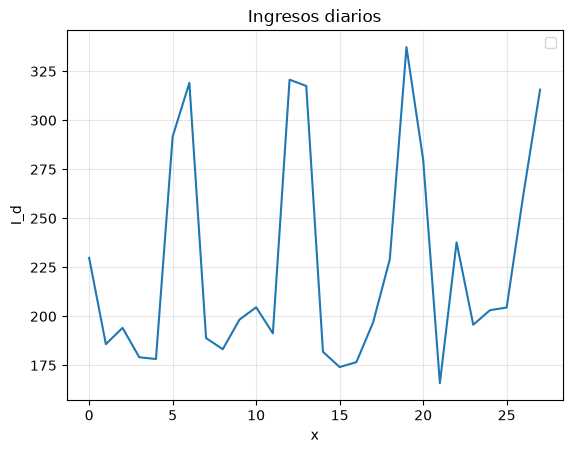

In [70]:
# Tu código aquí
x= np.arange(0,28,1)

fig, ax = plt.subplots()

ax.plot(x, ingresos_diarios)
ax.set_title("Ingresos diarios")
ax.set_xlabel("x")
ax.set_ylabel("I_d")
ax.legend()
ax.grid(True, alpha=0.3)

plt.show()

**Ejercicio 16.** Quiero comparar cuánto dinero generó cada producto en el mes.

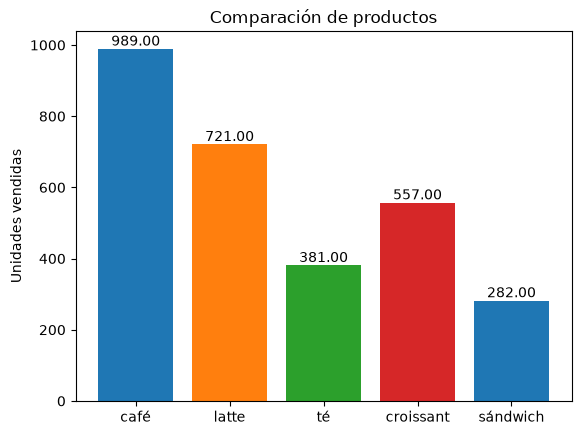

In [71]:
# Tu código aquí

fig, ax = plt.subplots()
barras = ax.bar(productos, ventas.sum(axis=0), color=["C0", "C1", "C2", "C3"])
ax.bar_label(barras, fmt="%.2f")          # escribe el valor encima de cada barra
ax.set_ylabel("Unidades vendidas")
ax.set_title("Comparación de productos")
plt.show()

**Ejercicio 17.** Quiero ver en un mismo gráfico las unidades vendidas cada día de los 5 productos, una línea por producto.

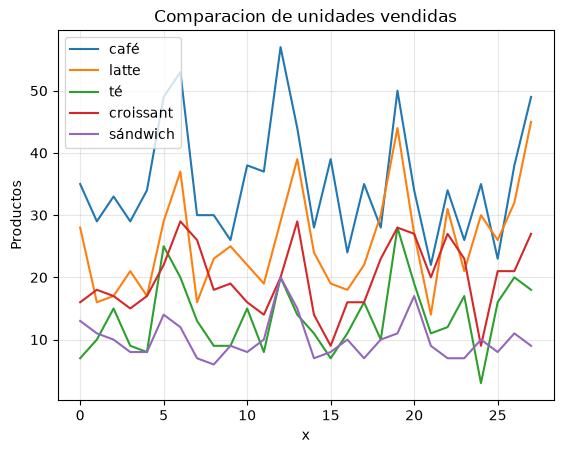

In [72]:
# Tu código aquí
fig, ax = plt.subplots()

ax.plot(x, ventas, label=productos)
ax.set_title("Comparacion de unidades vendidas")
ax.set_xlabel("x")
ax.set_ylabel("Productos")
ax.legend()
ax.grid(True, alpha=0.3)

plt.show()

**Ejercicio 18.** Quiero ver la matriz de ventas (días × productos) como un mapa de calor.

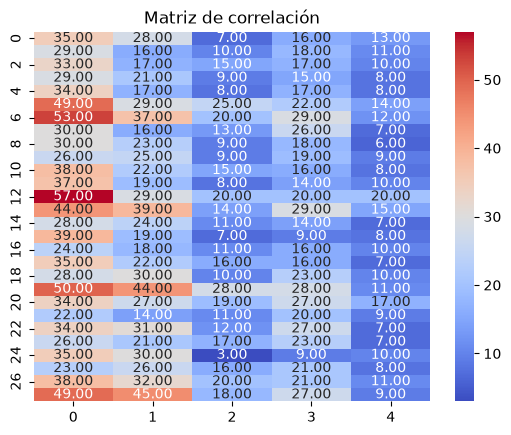

In [73]:
# Tu código aquí

fig, ax = plt.subplots()
sns.heatmap(ventas, annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
ax.set_title("Matriz de correlación")
plt.show()

### Con los datos de las propinas 💵

Usa el DataFrame `propinas` tal como quedó al final de la Parte 2.

**Ejercicio 19.** Quiero ver el histograma del importe de la cuenta.

TypeError: Data source must be a DataFrame or Mapping, not <class 'pandas.Series'>.

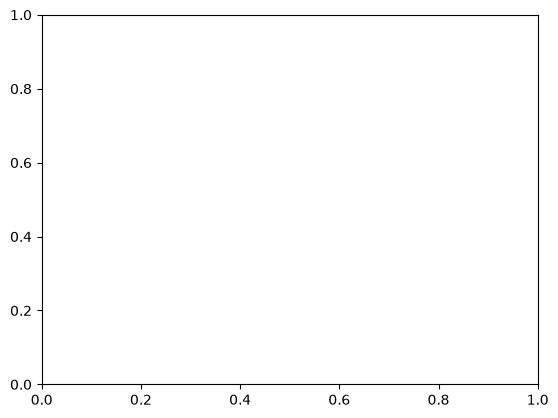

In [81]:
# Tu código aquí
fig, ax = plt.subplots()
sns.histplot(data=propinas_esp["cuenta"], x="dia", bins=30, ax=ax)
ax.axvline(propinas_esp["cuenta"].mean(), color="red", linestyle="--", label="media")
ax.set_title("Distribución de las cuentas")
ax.legend()
plt.show()

**Ejercicio 20.** Quiero visualizar la relación entre la cuenta y la propina.

In [ ]:
# Tu código aquí

**Ejercicio 21.** Quiero ver esa misma relación, pero distinguiendo las comidas de las cenas.

In [ ]:
# Tu código aquí

**Ejercicio 22.** Quiero ver si hay valores atípicos en el porcentaje de propina de cada día de la semana.

In [ ]:
# Tu código aquí

**Ejercicio 23.** Quiero ver cuántas mesas se atendieron cada día.

In [ ]:
# Tu código aquí

**Ejercicio 24.** Quiero comparar la propina media según el número de personas en la mesa, separando mesas de fumadores y de no fumadores.

In [ ]:
# Tu código aquí

### Con un dataset nuevo: los pingüinos 🐧

El archivo `data/penguins.csv` tiene medidas de 344 pingüinos de tres especies de la Antártida:

| Columna | Significado |
|---|---|
| `species` | especie: `Adelie`, `Chinstrap`, `Gentoo` |
| `island` | isla donde se registró |
| `bill_length_mm` | longitud del pico (mm) |
| `bill_depth_mm` | profundidad (altura) del pico (mm) |
| `flipper_length_mm` | longitud de la aleta (mm) |
| `body_mass_g` | peso (g) |
| `sex` | `Male` / `Female` |

**Ejercicio 25.** Carga los datos en un DataFrame llamado `pinguinos`. Quiero ver el histograma del peso de los pingüinos.

In [ ]:
# Tu código aquí

**Ejercicio 26.** Quiero ver si la distribución del peso cambia según la especie.

In [ ]:
# Tu código aquí

**Ejercicio 27.** Quiero ver si hay valores atípicos en la longitud de la aleta de cada especie.

In [ ]:
# Tu código aquí

**Ejercicio 28.** Quiero visualizar la relación entre la longitud y la profundidad del pico, distinguiendo las especies.

In [ ]:
# Tu código aquí

**Ejercicio 29.** Quiero ver en una sola figura el histograma de las cuatro medidas numéricas, cada una en su propio gráfico.

In [ ]:
# Tu código aquí

**Ejercicio 30.** Quiero ver qué medidas numéricas están más relacionadas entre sí.

In [ ]:
# Tu código aquí

**Ejercicio 31.** Quiero comparar el peso medio de cada especie, separando machos y hembras.

In [ ]:
# Tu código aquí